# Redfield Relaxation Manual Test

## What is tested

With a constant spectral density, Redfield relaxation must give the same result as the
equivalent thermal rates. This notebook simulates 2D time-resolved spectra with both
descriptions and compares them. The spectra are plotted for a visual check and are also
compared numerically.

## List of tests

**Simple tests** (`run_tests_simple`)

1. `test_single_triplet_spectra`: thermal-rate and Redfield contexts give the same spectrum for one triplet.

**Difficult tests** (`run_tests_difficult`)

2. `test_coupled_triplets_spectra`: products of contexts (`@`) give the same spectrum for a pair of coupled triplets.

## How to run

Run all cells. The last two cells call `run_tests_simple()` and `run_tests_difficult()`.
Each test prints one line when it passes and raises `AssertionError` when it fails. The
plots can be switched off with `show_plots=False`.

In [1]:
import math
import os
import sys

import matplotlib.pyplot as plt
import torch

# Makes MaRs importable when the notebook is run from the repository without installation
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..", "..")))

from mars import population, spectra_manager, spin_model, visualization
from mars.population import RedfieldRelaxationChannel

dtype = torch.float64
device = torch.device("cpu")

FREQUENCY = 9.8e9  # Hz
TEMPERATURE = 300.0  # K
FIELDS = torch.linspace(0.340, 0.360, 1000, dtype=dtype, device=device)  # T

# Largest allowed difference between the spectra, relative to the spectrum maximum
RELATIVE_TOLERANCE = 5e-3

# Nearly equal initial populations, normalized to 1
_POPULATIONS = [0.502, 0.502, 0.500]
INIT_POPULATIONS = [value / sum(_POPULATIONS) for value in _POPULATIONS]

DEPHASING = [1e4, 1e4, 1e4]  # 1/s

## Helper functions

In [2]:
def create_sample(electrons: list[float], electron_electron_pairs: list[tuple[int, int]]) -> spin_model.SolidSample:
    """Create a powder sample of triplets that share the same g-tensor and zero-field splitting."""
    g_tensor = spin_model.Interaction([2.002, 2.003, 2.01], dtype=dtype, device=device)
    zfs = spin_model.DEInteraction([140e6, 40e6], dtype=dtype, device=device)
    system = spin_model.SpinSystem(
        electrons=electrons,
        g_tensors=[g_tensor] * len(electrons),
        electron_electron=[(i, j, zfs) for i, j in electron_electron_pairs],
    )
    return spin_model.SolidSample(
        base_spin_system=system, ham_strain=0.0, gauss=0.0002, lorentz=0.0002, device=device, mesh=(20, 20), dtype=dtype
    )


def create_thermal_rates() -> torch.Tensor:
    """Return the thermal rates between neighboring levels, in 1/s."""
    return torch.tensor([[0.0, 1.0, 0.0], [1.0, 0.0, 1.0], [0.0, 1.0, 0.0]], device=device, dtype=dtype) * 50


def constant_spectral_density(omega_rad_s: torch.Tensor, temperature: torch.Tensor) -> torch.Tensor:
    """Return J(omega) = 1, which makes Redfield relaxation equivalent to fixed rates."""
    return torch.ones_like(omega_rad_s)


def create_redfield_channels() -> list[RedfieldRelaxationChannel]:
    """Create a Redfield channel whose operators reproduce the thermal rates."""
    thermal_rates = create_thermal_rates()
    operators = []
    for i, j in zip(*torch.nonzero(thermal_rates, as_tuple=True)):
        # Each pair of levels appears twice, so each operator carries half of the rate
        operator = torch.zeros_like(thermal_rates)
        operator[i, j] += math.sqrt(thermal_rates[i, j]) / math.sqrt(2)
        operator[j, i] += math.sqrt(thermal_rates[i, j]) / math.sqrt(2)
        operators.append((operator, None))
    return [RedfieldRelaxationChannel(operators, constant_spectral_density, "symmetric")]


def create_population_context(sample) -> population.Context:
    """Create the context that holds the initial populations."""
    return population.Context(
        sample=sample,
        basis="xyz",
        init_populations=INIT_POPULATIONS,
        decay_rates=None,
        device=device,
        dtype=dtype,
        enforce_secularity=False,
    )


def create_thermal_context(sample) -> population.Context:
    """Create the context with thermal rates and dephasing."""
    return population.Context(
        sample=sample,
        basis="xyz",
        init_populations=None,
        thermal_rates=create_thermal_rates(),
        device=device,
        dtype=dtype,
        dephasing=DEPHASING,
    )


def create_redfield_context(sample, **kwargs) -> population.Context:
    """Create the context with Redfield relaxation and dephasing."""
    return population.Context(
        sample=sample,
        basis="xyz",
        relaxation_coupling_channels=create_redfield_channels(),
        device=device,
        dtype=dtype,
        dephasing=DEPHASING,
        **kwargs,
    )


def simulate_spectrum(creator_class, sample, context, time: torch.Tensor) -> torch.Tensor:
    """Simulate the 2D time-resolved spectrum for the given context."""
    creator = creator_class(
        freq=FREQUENCY, sample=sample, harmonic=0, context=context, temperature=TEMPERATURE, device=device, dtype=dtype
    )
    return creator(sample, FIELDS, time)


def compare_spectra(creator_class, sample, context_thermal, context_redfield, time, show_plots: bool) -> float:
    """Simulate both spectra, optionally plot them and return their relative difference."""
    spectrum_thermal = simulate_spectrum(creator_class, sample, context_thermal, time)
    spectrum_redfield = simulate_spectrum(creator_class, sample, context_redfield, time)

    if show_plots:
        visualization.plot_2d_timeresolved(FIELDS, time, spectrum_thermal, time_unit="us")
        plt.show()
        visualization.plot_2d_timeresolved(FIELDS, time, spectrum_redfield, time_unit="us")
        plt.show()

    difference = (spectrum_thermal - spectrum_redfield).abs().max() / spectrum_thermal.abs().max()
    return difference.item()

## Simple tests

In [3]:
def test_single_triplet_spectra(show_plots: bool = True):
    """Check that thermal-rate and Redfield contexts give the same spectrum for one triplet."""
    sample = create_sample(electrons=[1.0], electron_electron_pairs=[(0, 0)])
    context_thermal = create_population_context(sample) + create_thermal_context(sample)
    context_redfield = create_population_context(sample) + create_redfield_context(sample)
    time = torch.linspace(0.0, 1e-3, 1800, dtype=dtype, device=device)

    difference = compare_spectra(
        spectra_manager.DensityTimeSpectra, sample, context_thermal, context_redfield, time, show_plots
    )

    assert difference < RELATIVE_TOLERANCE, f"The spectra differ by {difference:.2e} of the maximum"
    print(f"Single triplet test passed (spectra agree, relative difference is {difference:.1e})")

## Difficult tests

In [4]:
def test_coupled_triplets_spectra(show_plots: bool = True):
    """Check that products of thermal-rate and Redfield contexts give the same spectrum for coupled triplets."""
    single_triplet = create_sample(electrons=[1.0], electron_electron_pairs=[(0, 0)])
    sample = create_sample(electrons=[1.0, 1.0], electron_electron_pairs=[(0, 0), (1, 1), (0, 1)])

    populations = create_population_context(single_triplet)
    thermal = populations + create_thermal_context(single_triplet)
    context_thermal = thermal @ thermal

    # The two factors differ in the secularity setting
    context_redfield = (
        populations + create_redfield_context(single_triplet, enforce_secularity=False)
    ) @ (populations + create_redfield_context(single_triplet))
    time = torch.linspace(0.0, 100e-3, 800, dtype=dtype, device=device)

    difference = compare_spectra(
        spectra_manager.CoupledTimeSpectra, sample, context_thermal, context_redfield, time, show_plots
    )

    assert difference < RELATIVE_TOLERANCE, f"The spectra differ by {difference:.2e} of the maximum"
    print(f"Coupled triplets test passed (spectra agree, relative difference is {difference:.1e})")

## Run the tests

In [5]:
def run_tests_simple(show_plots: bool = True):
    """Run the test for one triplet."""
    test_single_triplet_spectra(show_plots)
    print("\nThe simple Redfield manual test passed.")


def run_tests_difficult(show_plots: bool = True):
    """Run the test for a pair of coupled triplets."""
    test_coupled_triplets_spectra(show_plots)
    print("\nThe difficult Redfield manual test passed.")

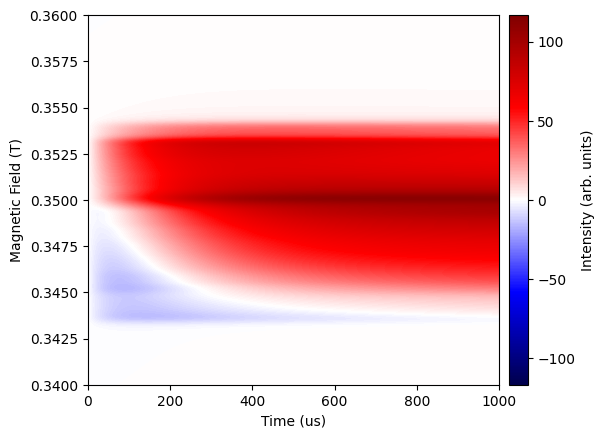

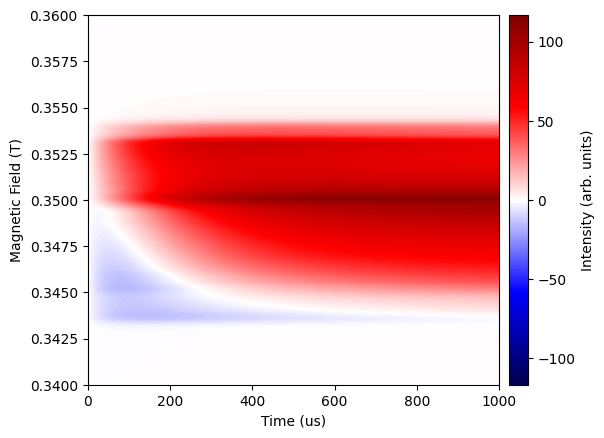

Single triplet test passed (spectra agree, relative difference is 1.5e-03)

The simple Redfield manual test passed.


In [6]:
run_tests_simple()

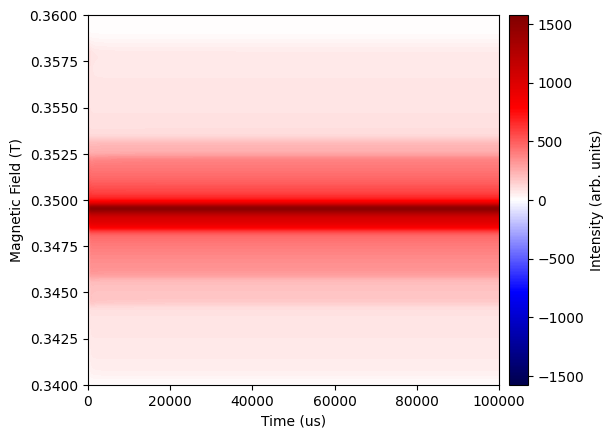

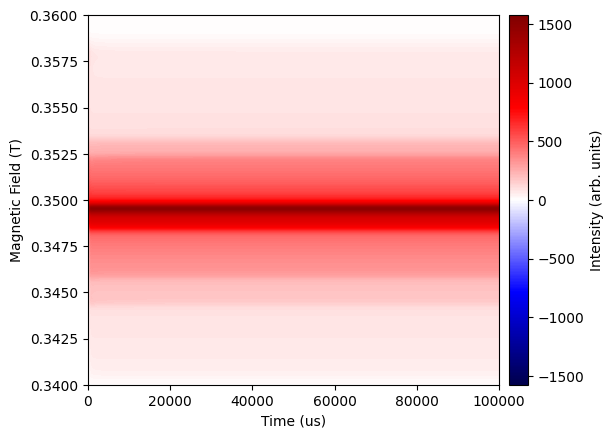

Coupled triplets test passed (spectra agree, relative difference is 1.2e-03)

The difficult Redfield manual test passed.


In [7]:
run_tests_difficult()